# Activity7.04: Top 30 music YouTube channels using FacetGrid

LU MENGJIE — MC643920  
Suggested Exercise 07 · Practice 02

Data: `YouTube.csv`. Historical snapshot as of January 2020; not a current ranking.

## Activity7.04 — 01. Read all 30 channels and convert columns to lists

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

DATA_DIR = Path('../../Datasets')
pd.set_option('display.max_columns', 8)
pd.set_option('display.width', 110)
print('LU MENGJIE | MC643920 | Python 3 / Seaborn', sns.__version__)
sns.set_theme()
mydata = pd.read_csv(DATA_DIR / 'YouTube.csv')
channels = mydata['Channel'].tolist()
subscribers = mydata['Subs (in millions)'].tolist()
views = mydata['Views (in millions)'].tolist()
print('Channel / subscriber / view list lengths:', len(channels), len(subscribers), len(views))
print('Column types after conversion:', type(channels).__name__, type(subscribers).__name__, type(views).__name__)
display(mydata.head())

LU MENGJIE | MC643920 | Python 3 / Seaborn 0.13.2
Channel / subscriber / view list lengths: 30 30 30
Column types after conversion: list list list


,Channel,Subs (in millions),Views (in millions)
0,T-Series,123.0,94410
1,Canal KondZilla,54.5,27860
2,Zee Music Company,48.5,22689
3,Ed Sheeran,43.2,18905
4,EminemMusic,40.2,773


## Activity7.04 — 02. Build the two-metric DataFrame

In [2]:
data = pd.DataFrame({
    'YouTube Channels': channels + channels,
    'Type': ['Subscribers'] * len(channels) + ['Views'] * len(channels),
    'Count (millions)': subscribers + views
})
print('Long-form shape:', data.shape)
display(data.groupby('Type')['Count (millions)'].agg(['count', 'min', 'max']))
display(data.head(4))

Long-form shape: (60, 3)


,count,min,max
Type,,,
Subscribers,30,25.8,123.0
Views,30,294.0,94410.0


,YouTube Channels,Type,Count (millions)
0,T-Series,Subscribers,123.0
1,Canal KondZilla,Subscribers,54.5
2,Zee Music Company,Subscribers,48.5
3,Ed Sheeran,Subscribers,43.2


## Activity7.04 — 03. Draw the two-column FacetGrid

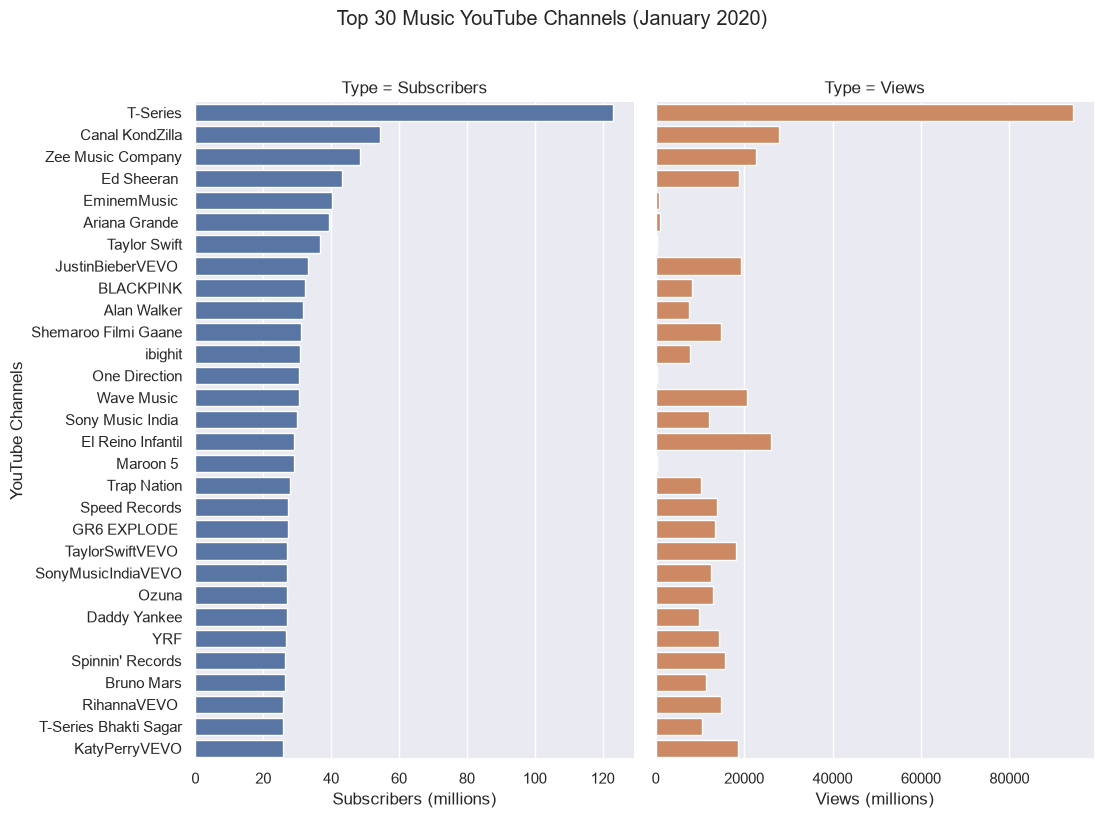

In [3]:
g = sns.FacetGrid(data, col='Type', col_order=['Subscribers', 'Views'],
                  hue='Type', sharex=False, sharey=True, height=8, aspect=0.7)
g.map_dataframe(sns.barplot, x='Count (millions)', y='YouTube Channels',
                order=channels, orient='h', errorbar=None)
g.set_titles('Type = {col_name}')
g.set_ylabels('YouTube Channels')
g.axes[0, 0].set_xlabel('Subscribers (millions)')
g.axes[0, 1].set_xlabel('Views (millions)')
g.figure.suptitle('Top 30 Music YouTube Channels (January 2020)', y=1.02)
g.figure.set_dpi(100)
g.tight_layout()
plt.show()

T-Series leads both metrics in this historical dataset. Separate horizontal scales avoid compressing subscriber values against much larger view totals. Views are correctly labelled as views, correcting the sample image's repeated subscriber label.